# Model evaluation: comparing the classifiers fairly

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 8 evaluation material (`00_week8_Evaluation.ipynb`) to the project data. It uses the same target, features and models as `logistic_regression.ipynb`, `knn.ipynb` and `decision_tree.ipynb`, and keeps the same 962 test adolescents.

**Learning goals (from Week 8), applied here**
- Explain why performance on training data is not enough.
- Use separate training, validation and test sets.
- Read a confusion matrix, and accuracy, precision, recall and F1.
- Compare models more fairly with 5-fold cross-validation.
- Avoid data leakage by putting preprocessing inside a `Pipeline`.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
)

# Fixing the random seed makes the splits and folds reproducible
RANDOM_STATE = 42

---
## Step 2. Load data and check the class balance

Same target and seven features as the other model notebooks. The class balance is checked first because it decides which metrics can be trusted.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
target = "depressed"   # 1 = BDI-II total >= 14, 0 = below

X = df[feature_cols]
y = df[target].astype(int)

print("X shape:", X.shape)
print(y.value_counts().rename({0: "not depressed", 1: "depressed"}))
print()
print(y.value_counts(normalize=True).rename({0: "not depressed", 1: "depressed"}).round(3))

X shape: (4810, 7)
depressed
not depressed    4023
depressed         787
Name: count, dtype: int64

depressed
not depressed    0.836
depressed        0.164
Name: proportion, dtype: float64


## **Explanation**

- 4,023 adolescents (83.6%) are below the threshold and 787 (16.4%) are above it, so the classes are **imbalanced**.
- A "model" that labels everyone *not depressed* is therefore right about 84% of the time without learning anything. This is the **baseline** for accuracy: a model has to beat it to show it has learned something.
- That baseline model has a recall of 0 (it catches nobody), which is why this notebook reports precision, recall and F1 next to accuracy, and ranks models by F1.

---
## Step 3. Split into training, validation and test sets

- **Training set:** fits the model.
- **Validation set:** compares models and settings.
- **Test set:** held back for one final, independent estimate.

The split is done in two stages, giving 60% / 20% / 20% as in the Week 8 notebook:
1. The **same 80/20 split as the other model notebooks** (seed 42), so the test set is the same 962 adolescents.
2. The remaining 80% is split again into training and validation. `stratify` keeps the share of depressed adolescents the same in both.

In [3]:
# Stage 1: identical to the other notebooks, so the test set is the same adolescents
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# Stage 2: 25% of the remaining 80% = 20% of all the data
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_trainval
)

for name, part in [("Train", y_train), ("Validation", y_valid), ("Test", y_test)]:
    print(f"{name:11s}{len(part):5d} rows ({len(part)/len(y):.0%})   "
          f"depressed: {part.sum():3d} ({part.mean():.1%})")

Train       2886 rows (60%)   depressed: 481 (16.7%)
Validation   962 rows (20%)   depressed: 160 (16.6%)
Test         962 rows (20%)   depressed: 146 (15.2%)


## **Explanation**

- 2,886 adolescents fit the models, 962 are used to compare them, and 962 are kept back for the end.
- The training and validation sets contain almost the same share of depressed adolescents (16.7% and 16.6%), because of `stratify`.
- The test set contains slightly fewer (15.2%). The first split is not stratified, to keep the test set identical to the one in the earlier notebooks, so this small difference is down to chance.
- The validation baseline (always "not depressed") is **83.4%**; the test baseline is **84.8%**.

---
## Step 4. Compare the three classifiers on the validation set

The models have the same settings as in their own notebooks: logistic regression, KNN with `k = 5`, and a decision tree with `max_depth = 3`.

Logistic regression and KNN are each placed in a `Pipeline` with a `StandardScaler`, so the scaler is fitted on the training data only. The tree needs no scaling.

The validation set chooses the winner. The test set is not touched.

In [4]:
def make_models():
    """Fresh, unfitted copies of the three classifiers."""
    return {
        "Logistic regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ]),
        "KNN (k = 5)": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ]),
        "Decision tree (depth 3)": DecisionTreeClassifier(
            max_depth=3, random_state=RANDOM_STATE
        ),
    }

models = make_models()

validation_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_rows.append({
        "Model": name,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "Flagged as depressed": int(pred.sum()),
        "Real cases caught": int(((pred == 1) & (y_valid == 1)).sum()),
    })

validation_results = pd.DataFrame(validation_rows).set_index("Model").sort_values("F1", ascending=False)
print(f"Validation baseline (always 'not depressed'): {(y_valid == 0).mean():.3f}")
validation_results.round(3)

Validation baseline (always 'not depressed'): 0.834


,Training accuracy,Accuracy,Precision,Recall,F1,Flagged as depressed,Real cases caught
Model,,,,,,,
Logistic regression,0.839,0.843,0.610,0.156,0.249,41,25
KNN (k = 5),0.855,0.823,0.424,0.175,0.248,66,28
Decision tree (depth 3),0.842,0.834,0.500,0.019,0.036,6,3


## **Explanation**

**How to read the columns** (all are measured on the 962 validation adolescents, 160 of whom are above the threshold)
- **Accuracy:** the share of all predictions that are correct.
- **Precision:** of the adolescents a model flags as depressed, the share who really are.
- **Recall:** of the 160 adolescents who really are above the threshold, the share the model catches.
- **F1:** combines precision and recall; it is low if either one is low.

**What the table shows**
- **Accuracy is close to the 83.4% baseline for every model.** Logistic regression (84.3%) is the only one above it, and only by about 9 adolescents. KNN (82.3%) is below it.
- **Recall is low everywhere.** Logistic regression catches 25 of 160 (0.16), KNN 28 (0.18), and the tree only 3 (0.02).
- **Logistic regression and KNN are almost tied on F1** (0.249 and 0.248), but in different ways. Logistic regression flags fewer adolescents (41) and is right more often (precision 0.61); KNN flags more (66), catches three more real cases, and is right less often (precision 0.42).
- **The tree's F1 (0.036) is far lower** because it flags only 6 adolescents in total.
- **Training accuracy is close to validation accuracy** for all three, so none of them is badly overfitting. They miss cases because the seven features do not separate the two groups well, not because they have memorised the training data.

**Which metric matters here?** The model is meant to identify adolescents above a clinical threshold. Missing one (a false negative) is arguably the more costly error, so recall deserves the most attention, with precision showing the price paid in false alarms.

---
## Step 5. Read the confusion matrix of the selected model

The model with the highest validation F1 is selected. In scikit-learn, **rows are the actual classes and columns are the predicted classes**, with "not depressed" (0) first:

- **True negative (TN):** predicted not depressed, actually not depressed (top-left)
- **False positive (FP):** predicted depressed, actually not depressed (top-right)
- **False negative (FN):** predicted not depressed, actually depressed (bottom-left)
- **True positive (TP):** predicted depressed, actually depressed (bottom-right)

Selected using validation F1: Logistic regression
Confusion matrix (actual rows, predicted columns):
[[786  16]
 [135  25]]


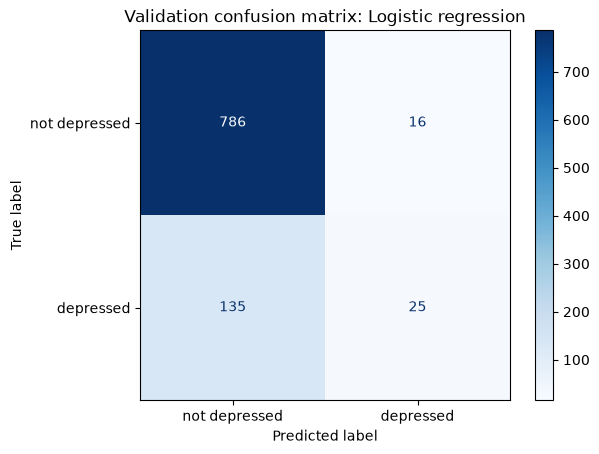

In [5]:
# Choose the model with the highest validation F1 score
best_name = validation_results.index[0]
best_model = models[best_name]
valid_pred = best_model.predict(X_valid)

print("Selected using validation F1:", best_name)
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_valid, valid_pred, labels=[0, 1]))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_pred, labels=[0, 1],
    display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title(f"Validation confusion matrix: {best_name}")
plt.show()

## **Explanation**

Logistic regression is selected, by a margin of 0.001 in F1 over KNN.

- **786 true negatives:** adolescents below the threshold, correctly labelled.
- **25 true positives:** adolescents above the threshold, correctly flagged.
- **16 false positives:** flagged, but actually below the threshold (false alarms).
- **135 false negatives:** above the threshold, but not flagged (misses).

**Reading it three ways**
- **Diagonal (accuracy):** (786 + 25) / 962 = 84.3%.
- **Down the "depressed" column (precision):** 25 of the 41 flagged are real cases = 0.61.
- **Across the "depressed" row (recall):** 25 of the 160 real cases are caught = 0.16.

The errors are very one-sided: 135 misses against 16 false alarms. The model is cautious. It rarely flags anyone, so its accuracy looks fine, but it overlooks about 5 in every 6 adolescents above the threshold. The accuracy figure alone hides this completely.

---
## Step 6. Cross-validation for a more stable comparison

A single validation split depends on which adolescents happened to be held out, and Step 4 was decided by 0.001. In **5-fold cross-validation** the training data is divided into five folds. Each fold is the validation set once, while the model is fitted on the other four. This gives five scores per model, reported as a mean and a standard deviation (SD).

As in the Week 8 notebook, cross-validation is run on the training set only. `StratifiedKFold` keeps the share of depressed adolescents the same in every fold. The test set stays untouched.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
fold_f1 = {}   # keep the five F1 scores per model to look at their spread
for name, model in models.items():
    # cross_validate refits the model once per fold and scores the held-out fold
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"],
        return_train_score=False
    )
    fold_f1[name] = scores["test_f1"]
    cv_rows.append({
        "Model": name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Precision mean": scores["test_precision"].mean(),
        "Recall mean": scores["test_recall"].mean(),
        "F1 mean": scores["test_f1"].mean(),
        "F1 SD": scores["test_f1"].std(),
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model").sort_values("F1 mean", ascending=False)
display(cv_results.round(3))

print("F1 in each of the five folds:")
pd.DataFrame(fold_f1, index=[f"fold {i}" for i in range(1, 6)]).T.round(3)

,Accuracy mean,Accuracy SD,Precision mean,Recall mean,F1 mean,F1 SD
Model,,,,,,
Decision tree (depth 3),0.837,0.004,0.551,0.185,0.256,0.125
KNN (k = 5),0.814,0.005,0.375,0.173,0.236,0.026
Logistic regression,0.836,0.008,0.548,0.139,0.220,0.037


F1 in each of the five folds:


,fold 1,fold 2,fold 3,fold 4,fold 5
Logistic regression,0.256,0.153,0.252,0.226,0.212
KNN (k = 5),0.225,0.250,0.194,0.239,0.271
Decision tree (depth 3),0.338,0.384,0.112,0.096,0.350


## **Explanation**

- **The ranking changes.** On the single validation split the order was logistic regression, KNN, tree. With cross-validation it is tree (mean F1 0.256), KNN (0.236), logistic regression (0.220).
- **The differences are smaller than the spread.** The three means are within 0.04 of each other, while the SDs run from 0.03 to 0.13. No model is reliably better than the others on F1.
- **The decision tree is the least stable.** Its F1 is about 0.34 to 0.38 in three folds and about 0.10 in the other two (SD 0.125). With `max_depth = 3`, one split landing slightly differently switches a large leaf between "depressed" and "not depressed". Its validation F1 of 0.036 in Step 4 was one of its bad draws, and its top place here rests on its good ones.
- **KNN and logistic regression are steadier** (SD 0.026 and 0.037), so their scores can be trusted more even though they are not higher.
- **Accuracy barely moves** (SD under 0.01, all between 0.81 and 0.84), again close to the baseline of about 0.83.

**What this shows:** a single validation split can pick a "winner" by luck. Cross-validation gives the same models five different exams, and here it shows that the honest conclusion is "no clear winner, and recall is low for all three" (0.14 to 0.19).

---
## Step 7. Data leakage: why the scaler sits inside the pipeline

**Data leakage** happens when information from the validation or test data influences model fitting, which makes the evaluation look better than it really is.

- **Incorrect:** fit a scaler on the whole dataset before splitting. Its mean and standard deviation then include the held-out adolescents.
- **Correct:** put the scaler and the model in a `Pipeline`. During cross-validation the scaler is refitted inside each set of four training folds and only applied to the fifth.

`knn.ipynb` fitted its scaler on the training set by hand, which is correct for one split. With five folds the training rows change every round, so the pipeline does this automatically.

In [7]:
# Correct pattern: preprocessing is inside the pipeline
safe_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

safe_scores = cross_validate(
    safe_model, X_train, y_train, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("Mean CV F1 with pipeline:", round(safe_scores["test_f1"].mean(), 3))

Mean CV F1 with pipeline: 0.22


## **Explanation**

- The result (0.220) is the logistic regression figure from Step 6, because the models there were already pipelines.
- In each of the five rounds the scaler learned its mean and standard deviation from four folds only, so the held-out fold stayed unseen.
- The same rule applied earlier in the project: `depressed` is derived from `bdi_total` and the `bdi_item_*` columns, so those were left out of the features. Including them would be leakage of a different kind, information that would not be available at prediction time.

---
## Step 8. Final evaluation on the test set

The selected model is re-created with the same settings, refitted on the training plus validation data (the 3,848 adolescents used for training in the other notebooks), and then evaluated on the test set.

The model is not changed after this. Adjusting it in response to test results would turn the test set into another validation set.

Final selected model: Logistic regression
Test baseline (always 'not depressed'): 0.848
Accuracy:  0.849
Precision: 0.511
Recall:    0.158
F1:        0.241


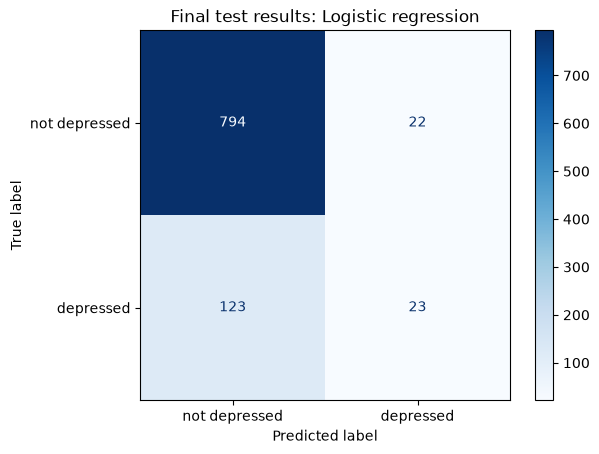

In [8]:
# Re-create the selected model and fit on train + validation
final_model = make_models()[best_name]
final_model.fit(X_trainval, y_trainval)
test_pred = final_model.predict(X_test)

print("Final selected model:", best_name)
print(f"Test baseline (always 'not depressed'): {(y_test == 0).mean():.3f}")
print(f"Accuracy:  {accuracy_score(y_test, test_pred):.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.3f}")
print(f"Recall:    {recall_score(y_test, test_pred):.3f}")
print(f"F1:        {f1_score(y_test, test_pred):.3f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["not depressed", "depressed"], cmap="Blues"
)
plt.title(f"Final test results: {best_name}")
plt.show()

## **Explanation**

- **Accuracy 0.849 against a baseline of 0.848.** Logistic regression labels one more adolescent correctly than a model that predicts "not depressed" for everyone.
- **Confusion matrix:** 794 true negatives, 22 false positives, 123 false negatives, 23 true positives.
- **Precision 0.51:** about half of the 45 adolescents it flags really are above the threshold.
- **Recall 0.16:** it catches 23 of the 146 real cases and misses 123.
- **The test result matches the validation and cross-validation results** (recall 0.14 to 0.16, F1 0.22 to 0.25). The model generalises as expected; it is simply not a strong classifier.
- These are the same numbers as in `logistic_regression.ipynb`, because the model was fitted on the same 3,848 adolescents and tested on the same 962.

> **Caveat:** this test set was already looked at in `logistic_regression.ipynb`, `knn.ipynb` and `decision_tree.ipynb`, so it is no longer strictly "used once". No setting in this notebook was chosen from it, but the earlier notebooks did compare models on it. The cross-validation results in Step 6 are the fairest comparison of the three models.

---
## Summary of findings

- **Accuracy is misleading on this data.** With 84% of adolescents below the threshold, every model scores between 0.81 and 0.85, about the same as predicting "not depressed" for everyone.
- **Precision, recall and F1 show the real picture.** All three models catch fewer than 1 in 5 adolescents above the threshold. Logistic regression is the most precise; KNN flags more and is right less often.
- **Cross-validation changed the conclusion.** One validation split put logistic regression first and the tree last; five folds put the tree first, with a spread (SD 0.125) larger than the gaps between the models. There is no clear winner.
- **The pipeline keeps the comparison honest** by fitting the scaler on training folds only.
- **On the test set**, logistic regression reaches accuracy 0.849 and recall 0.158, in line with what cross-validation predicted.

**Key message (Week 8):** models are chosen with training data plus validation or cross-validation, the test set is kept for the final estimate, and the metric has to match the problem. For this research question the metric that matters most is recall, and none of the three single models does well on it.